# Elastic Net: Mixing L1 and L2 Penalties

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `diabetes` | **Runs on:** CPU, about 1 minute(s)

Balance sparsity and stability when predictors are correlated.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How the mixing ratio blends lasso and ridge
- Why the elastic net handles correlated groups better than lasso
- How to tune two parameters sensibly

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Serum measures `s1` to `s6` move together, so a method that picks one and drops the rest is fragile.

**The problem.** Predict diabetes progression with a model that is sparse but keeps correlated groups together.

**Why it matters.** Stable selection matters when the selected list is used in a clinical score.

**Why machine learning.** Correlation structure is learned from data.

**Why this algorithm.** The elastic net was designed for exactly this case.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Regularization and Variable Selection Via the Elastic Net

- **Type:** foundational paper
- **Authors:** Zou, H. and Hastie, T.
- **Year and venue:** 2005, Journal of the Royal Statistical Society B 67(2):301-320
- **DOI or URL:** https://doi.org/10.1111/j.1467-9868.2005.00503.x
- **Verification:** Crossref 2026-11-17
- **Research objective:** Combine L1 and L2 penalties to handle correlated predictors.
- **Methodology:** Penalty that mixes lasso and ridge terms, solved by a LARS style algorithm.
- **Dataset:** Prostate cancer, simulations and gene expression data.
- **Main findings:** Selects groups of correlated variables and outperforms the lasso when predictors are correlated.
- **Limitations:** Two tuning parameters instead of one.

### Least angle regression

- **Type:** foundational paper
- **Authors:** Efron, B., Hastie, T., Johnstone, I. and Tibshirani, R.
- **Year and venue:** 2004, The Annals of Statistics 32(2):407-499
- **DOI or URL:** https://doi.org/10.1214/009053604000000067
- **Verification:** Crossref 2026-11-17
- **Research objective:** Give an efficient path algorithm for the lasso and related methods.
- **Methodology:** Move coefficients along the direction equiangular to the active predictors.
- **Dataset:** The diabetes progression data of 442 patients used in this repository.
- **Main findings:** The full lasso path costs about the same as one least squares fit.
- **Limitations:** Sensitive to noise when predictors are strongly correlated.

**Relationship to this notebook.** Zou and Hastie propose the elastic net for correlated predictors. We apply it to the correlated serum measures of the diabetes data without reproducing their experiments. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Objective.**

$$\min_\beta \; \frac{1}{2n}\lVert y - A\beta \rVert_2^2 + \alpha\Big(\rho \lVert \beta \rVert_1 + \frac{1-\rho}{2}\lVert \beta \rVert_2^2\Big)$$

where $\rho \in [0,1]$ is `l1_ratio`. $\rho=1$ is the lasso and $\rho \to 0$ approaches ridge.

**Grouping effect.** The quadratic term makes the objective strictly convex, so highly correlated features receive similar coefficients.

**Optimisation.** Coordinate descent with a soft threshold divided by $1 + \alpha(1-\rho)$.

**Limitations.** Two parameters to tune, still linear.

## 5. Dataset Introduction

**Diabetes progression** from Efron, Hastie, Johnstone and Tibshirani (2004), shipped with scikit-learn. 442 patients, 10 baseline features (`age`, `sex`, `bmi`, `bp`, and six blood serum measures `s1` to `s6`), target is a quantitative measure of disease progression one year after baseline. The provider centred and scaled the features. Data terms of the original source are not stated by the provider. Limits: small sample, no time dimension, `sex` is a standardised number.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet, Lasso
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "elastic_net"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("diabetes")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: regression | target: progression | shape: (442, 11)


,source
title,Diabetes disease progression
source,"Efron, Hastie, Johnstone, Tibshirani (2004), L..."
url,https://www4.stat.ncsu.edu/~boos/var.select/di...
license,distributed with scikit-learn (BSD-3-Clause pa...
doi,None
rows,442
features,10
limits,Features are mean centred and scaled by the pr...


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (442, 11)


,columns by dtype
float64,11


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


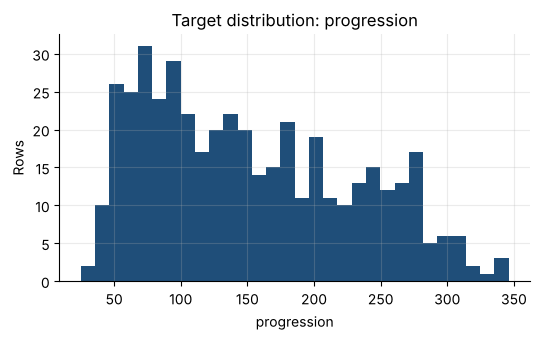

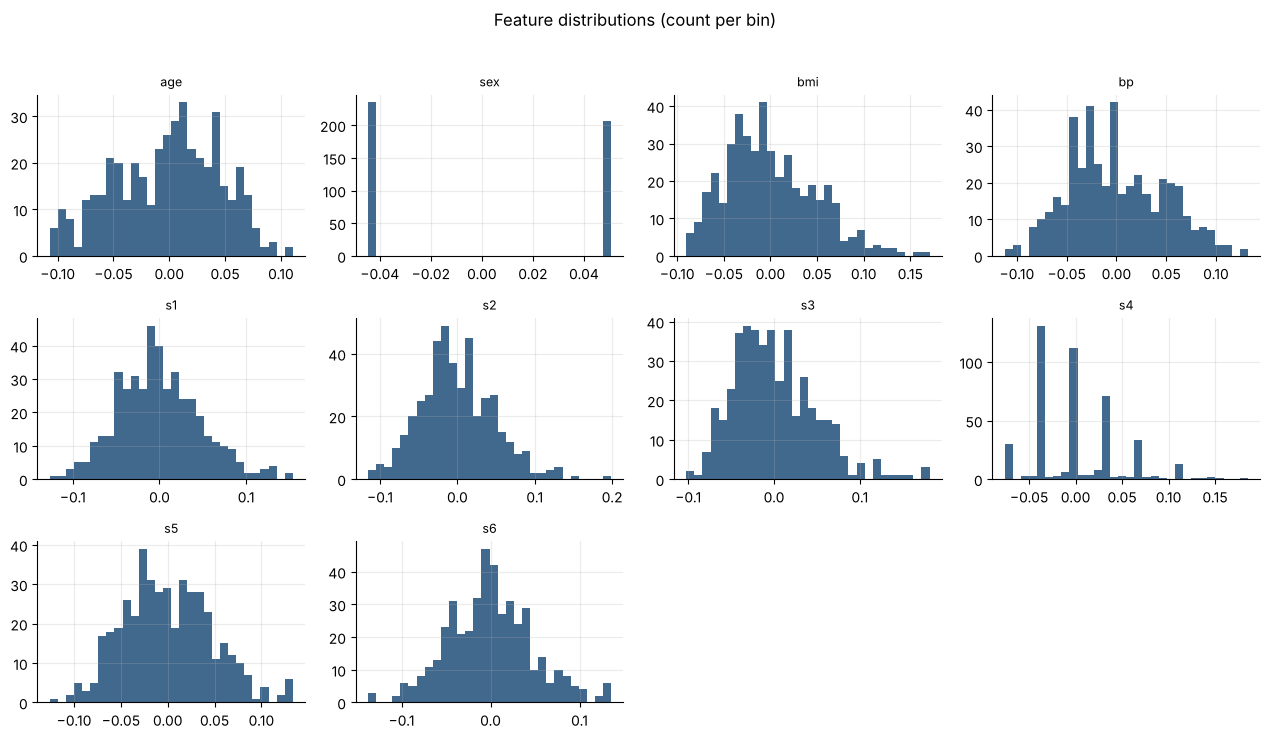

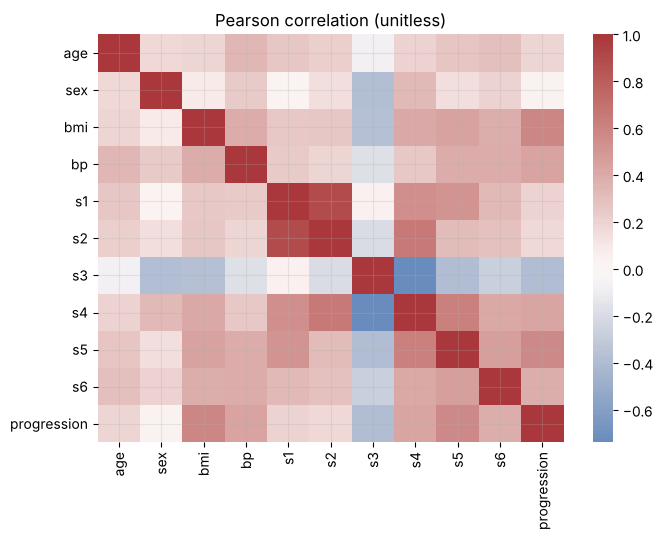

,feature,outliers,percent
0,s6,9,2.04
1,s1,8,1.81
2,s3,7,1.58
3,s2,7,1.58
4,s5,4,0.90
5,bmi,3,0.68
6,s4,2,0.45
7,age,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 264 89 89
transformed train shape: (264, 10)


## 8. Algorithm Implementation

### 8.1 Concept

Think of the elastic net as the lasso with a ridge stabiliser. The L2 term spreads weight over correlated features, the L1 term still removes weak ones.

### 8.2 Python implementation from scratch

Not implemented from scratch: the update is the lasso coordinate descent from the previous notebook with a modified denominator.

### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `alpha` | Overall penalty strength. |
| `l1_ratio` | Share of L1 in the penalty. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [6]:
SELECT = "RMSE"
LOWER_IS_BETTER = True
SCORING = "neg_root_mean_squared_error"
SWEEP_PARAM = "model__l1_ratio"
SWEEP_VALUES = [0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]

def build_pipeline():
    return make_model_pipeline(X_train, ElasticNet(alpha=0.1, max_iter=10000), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

ElasticNet(alpha=0.1, max_iter=10000)


,RMSE,R2,MAE
model__l1_ratio,,,
0.05,51.2025,0.5215,42.7069
0.10,51.1978,0.5216,42.6985
0.30,51.1800,0.5219,42.6653
0.50,51.1619,0.5222,42.6327
0.70,51.1366,0.5227,42.5997
0.90,51.1331,0.5228,42.6178
1.00,51.0997,0.5234,42.6424


best model__l1_ratio on validation: 1.0
refit on train plus validation rows


## 10. Evaluation

Regression metrics: MAE (average absolute error in target units), RMSE (square root of the mean squared error, same unit, punishes large errors), R-squared (share of variance explained, can be negative on new data) and MAPE when the target is never zero.

A dummy model gives the floor every real model must beat.

In [7]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "ElasticNet": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="ElasticNet", dataset="diabetes",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,MAE,MSE,RMSE,R2,MAPE_percent
baseline,64.0065,5361.5335,73.2225,-0.0120,62.7918
ElasticNet,42.8052,2884.6243,53.7087,0.4555,37.4143


5-fold CV neg_root_mean_squared_error: mean -55.0229, std 4.1328
saved elastic_net.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

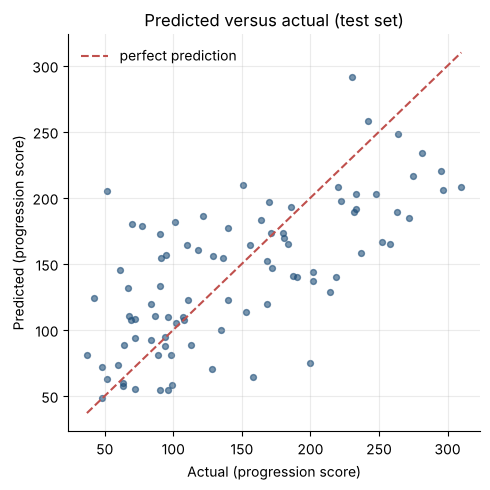

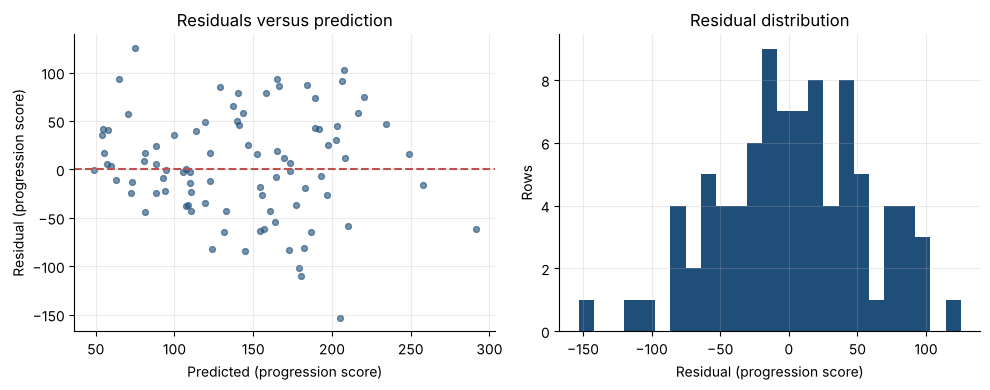

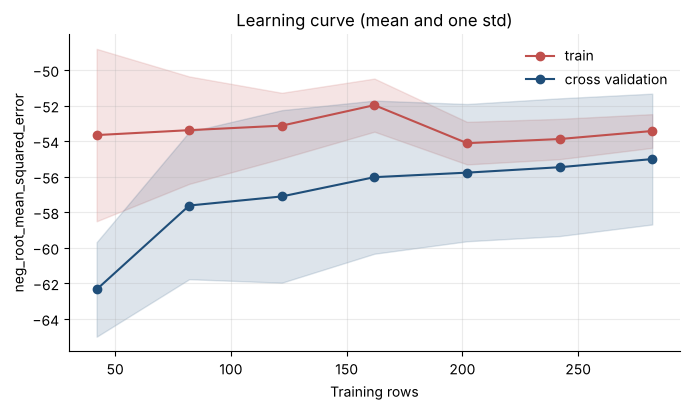

In [8]:
pred = final_model.predict(X_test)
fig = viz.plot_pred_vs_actual(y_test, pred, unit="(progression score)")
save_figure(fig, NOTEBOOK_ID, "pred_vs_actual"); plt.show()
fig = viz.plot_residuals(y_test, pred, unit="(progression score)")
save_figure(fig, NOTEBOOK_ID, "residuals"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()

## 12. Interpretation

Permutation importance shuffles one feature and measures how much the error grows. Correlated features share importance, so read it as a ranking of groups. Check the residual plot for curvature or funnel shapes, which mean the model misses structure or the error variance changes with the prediction.

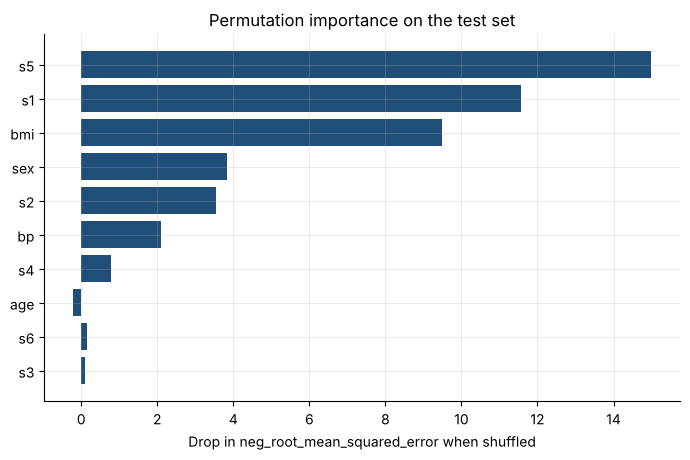

Top features: s5, s1, bmi, sex, s2
Largest test errors:


,actual,predicted,abs_error
56,52.0,205.195,153.195
77,200.0,74.619,125.381
211,70.0,180.323,110.323
9,310.0,207.867,102.133
209,77.0,178.947,101.947



Test RMSE: 53.7087 | baseline RMSE: 73.2225
Cross validation spread (std): 4.1328. A test gap larger than this spread is meaningful.


In [9]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Grouping effect on correlated copies

Duplicate `bmi` with tiny noise. Lasso tends to keep one copy, the elastic net shares weight.

In [10]:
rng = np.random.default_rng(SEED)
Z = StandardScaler().fit_transform(X_trainval)
copy = Z[:, [list(X_trainval.columns).index("bmi")]] + rng.normal(0, 0.01, (len(Z), 1))
Z2 = np.c_[Z, copy]
bmi_cols = [list(X_trainval.columns).index("bmi"), Z2.shape[1] - 1]
for name, m in [("Lasso", Lasso(alpha=0.3, max_iter=10000)), ("ElasticNet l1_ratio=0.3", ElasticNet(alpha=0.3, l1_ratio=0.3, max_iter=10000))]:
    coef = m.fit(Z2, y_trainval).coef_
    print(name, "coefficients on bmi and its copy:", coef[bmi_cols].round(2))

Lasso coefficients on bmi and its copy: [26.21  0.  ]
ElasticNet l1_ratio=0.3 coefficients on bmi and its copy: [12.83 12.77]


### Experiment 2: Two parameter grid

Cross validated RMSE over alpha and l1_ratio.

In [11]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(make_model_pipeline(X_trainval, ElasticNet(max_iter=10000)),
                    {"model__alpha": [0.01, 0.1, 0.3, 1], "model__l1_ratio": [0.1, 0.5, 0.9]},
                    scoring="neg_root_mean_squared_error", cv=5).fit(X_trainval, y_trainval)
res = pd.DataFrame(grid.cv_results_)
display(res.pivot_table(index="param_model__alpha", columns="param_model__l1_ratio", values="mean_test_score").mul(-1).round(2))
print("best:", grid.best_params_)

param_model__l1_ratio,0.1,0.5,0.9
param_model__alpha,,,
0.01,55.02,55.01,55.02
0.10,55.08,55.06,55.04
0.30,55.43,55.18,55.06
1.00,57.65,56.35,55.27


best: {'model__alpha': 0.01, 'model__l1_ratio': 0.5}


### Experiment 3: Sparsity of the three penalties

Count zero coefficients for ridge, lasso and elastic net at similar strength.

In [12]:
from sklearn.linear_model import Ridge
for name, m in [("Ridge", Ridge(alpha=10)), ("Lasso", Lasso(alpha=1.0, max_iter=10000)), ("ElasticNet", ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000))]:
    coef = m.fit(Xtr, y_train).coef_
    print(f"{name}: zero coefficients {(coef == 0).sum()} of {len(coef)}")

Ridge: zero coefficients 0 of 10
Lasso: zero coefficients 1 of 10
ElasticNet: zero coefficients 0 of 10


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Add one more feature or remove one and explain the change using cross validation.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Zou and Hastie argue that the elastic net selects correlated groups together. Our duplicate feature experiment is a small controlled check of that claim, not a reproduction of their data.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Use `ElasticNetCV`, repeated cross validation and compare with group lasso if feature groups are known.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Elastic net sits between lasso and ridge.
- It shares weight across correlated features.
- Tune alpha and l1_ratio together.

**Use cases.** Genomics, finance and any wide correlated data.

**Limitations.** Two parameters, linear only.

**Recommended next notebook.** Support Vector Regression.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.